<a href="https://colab.research.google.com/github/AshleyH2026/A05-pca/blob/main/notebook_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle
import matplotlib.pyplot as plt

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()


Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ashley Hughes

**Date:** 10/19/2026

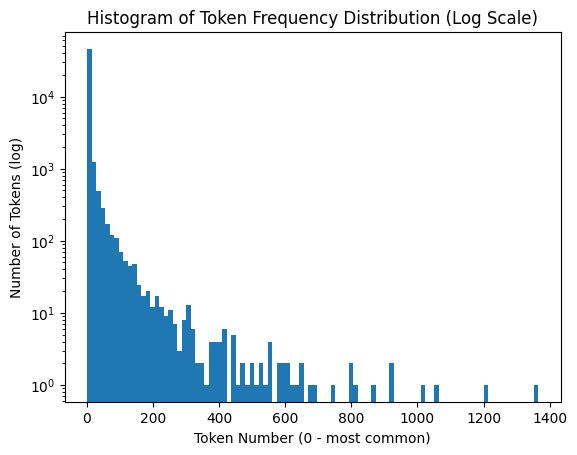


 The distribution shows a strong right skew. The top five most common words were 'new', 'date', 'get', 'please', and 'enron'. The distribution indicates that there are a few words that appear a lot, and there are a great many words that appear only a few times.


In [20]:
# Your Phase 1 solution to the problem goes here.
# Q1

import pickle
import matplotlib.pyplot as plt
import pandas as pd

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
#print(token_freq)

# Plot histogram of token

# Take frequency counts out of nested tuple and put in list
frequencies = [count for token, count in token_freq]
#print(frequencies)

# Use log scale to adjust for strong right skew
plt.hist(frequencies, bins=100, log=True)
plt.title('Histogram of Token Frequency Distribution (Log Scale)')
plt.xlabel('Token Number (0 - most common)')
plt.ylabel('Number of Tokens (log)')
plt.show()

print("\n The distribution shows a strong right skew. The top five most common words were 'new', 'date', 'get', 'please', and 'enron'. The distribution indicates that there are a few words that appear a lot, and there are a great many words that appear only a few times.")



In [13]:
# Q2
import pyarrow.parquet as pa
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

df = pd.read_parquet('Phishing_clean.parquet')
#df.head()

# Split into 80/20

eval_X_raw = df.drop(columns=["Email Type"])
eval_y = df["Email Type"]

eval_X_train_raw, eval_X_valid_raw, eval_y_train, eval_y_valid = train_test_split(
    eval_X_raw, eval_y, test_size=0.2, random_state=55, stratify=eval_y
)

# Run regression of y on one-hot-encoded emails

model = LinearRegression()
model.fit(eval_X_train_raw, eval_y_train)
train_r2 = model.score(eval_X_train_raw, eval_y_train)
test_r2 = model.score(eval_X_valid_raw, eval_y_valid)

print("Training R^2: " + str(train_r2))
print("Test R^2: " + str(test_r2))

# What words have the largest coefficients in absolute value and most strongly influence predictions?
coefficients = pd.Series(model.coef_, index=eval_X_train_raw.columns)

print("\nTop 10 Tokens By Absolute Coefficient:")
print(coefficients.abs().sort_values(ascending=False).head(10))

print("\nTop 5 Phishing-Associated Tokens:")
print(coefficients.sort_values(ascending=False).head(5))

print("\nTop 5 Legitimate-Associated Tokens")
print(coefficients.sort_values(ascending=True).head(5))



Training R^2: 0.7685962235561599
Test R^2: 0.6605364407256575

Top 10 Tokens By Absolute Coefficient:
background-image:    0.894673
localized            0.734777
transcript           0.704384
thermal              0.608732
rhythm               0.575916
aging                0.562800
cnet                 0.512514
xanaax               0.489885
april's              0.465511
premature            0.454109
dtype: float64

Top 5 Phishing-Associated Tokens:
localized     0.734777
transcript    0.704384
thermal       0.608732
rhythm        0.575916
aging         0.562800
dtype: float64

Top 5 Legitimate-Associated Tokens
background-image:   -0.894673
cnet                -0.512514
april's             -0.465511
intervention        -0.432339
shopper             -0.408262
dtype: float64


Rows and score columns: (18634, 2)
Sklearn: [0.01113086 0.00861037]
Cumulative variance: 0.019741231506382823


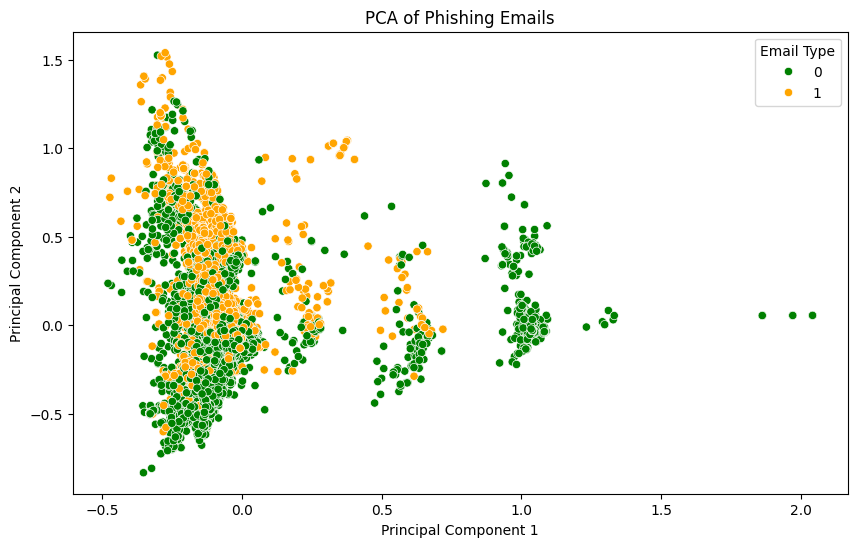


It appears that phishing and legitimate emails have a lot of overlap in what words they
use. However, there are some clusters free of phishing words (on the right of the graph 
past 1 on the x-axis), which appear to signal that it is a legitimate email.



In [14]:
# Q3
from sklearn.decomposition import PCA
import seaborn as sns

# PCA

pca = PCA(n_components=2).fit(eval_X_raw)
X_pca = pca.transform(eval_X_raw)

print("Rows and score columns:", X_pca.shape)
print("Sklearn:", pca.explained_variance_ratio_)
print("Cumulative variance:", np.sum(pca.explained_variance_ratio_) )

# Scatterplot

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=eval_y,
    palette= {0: 'green', 1: 'orange'},
)

plt.title('PCA of Phishing Emails')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

print("""
It appears that phishing and legitimate emails have a lot of overlap in what words they
use. However, there are some clusters free of phishing words (on the right of the graph
past 1 on the x-axis), which appear to signal that it is a legitimate email.
""")


In [17]:
# Q4

pca_2610 = PCA(n_components=2610)
X_train_pca = pca_2610.fit_transform(eval_X_train_raw)
X_test_pca = pca_2610.transform(eval_X_valid_raw)

# Linear Regression
model = LinearRegression()
model.fit(X_train_pca, eval_y_train)

y_train_pred = model.predict(X_train_pca)
y_test_pred = model.predict(X_test_pca)

# R^2 scores
r2_train = model.score(X_train_pca, eval_y_train)
r2_test = model.score(X_test_pca, eval_y_valid)

print("Training R^2: ", r2_train)
print("Test R^2: ", r2_test)
print("""
We see with this data that using PCA only gave a very slightly lower R^2 scores despite
using less data, which makes sense because information was lost. However, it is still
pretty similar, so the PCA seems to have gotten a good overview of the data.
""")


Training R^2:  0.767955967872377
Test R^2:  0.6602917491164377

We see with this data that using PCA only gave a very slightly lower R^2 scores despite
using less data, which makes sense because information was lost. However, it is still
pretty similar, so the PCA seems to have gotten a good overview of the data.



In [18]:
# Q5

# Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

print("""
Principal Component Analysis is the process of dimension reduction while retaining variance.
Essentially, it allows us to summarize data variation with fewer variables.
Some advantages to using PCA is that it can help reduce noise and the amount of storage
needed (because fewer dimensions are represented).

We see with this data that using PCA only gave a very slightly lower R^2 scores despite
using less data, which makes sense because information was lost but is impressive that it could
still retain such a similar R^2 value. This indicates that the PCA summarized the variation
well, while using much less storage and memory.
""")



Principal Component Analysis is the process of dimension reduction while retaining variance.
Essentially, it allows us to summarize data variation with fewer variables. 
Some advantages to using PCA is that it can help reduce noise and the amount of storage
needed (because fewer dimensions are represented).

We see with this data that using PCA only gave a very slightly lower R^2 scores despite
using less data, which makes sense because information was lost but is impressive that it could
still retain such a similar R^2 value. This indicates that the PCA summarized the variation
well, while using much less storage and memory.



## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** e2748d1eaf1e22b1b290c843ad2485b41c865862
- **AI tool and model used:** Gemini 3.8 Flash

### *Prompts used

1. Read through the prompt and edit the code provided below to ensure that 1) it meets the standards and requirements of the prompt, 2) is streamlined and optimized for efficiency and readability. For each change, list reasons why you made the change, what it improved and how much of a difference it made, and how the new code works. *pasted all code above (from phase 1) and prompt
2. Why do we not need:
y_train_pred = model.predict(X_train_pca)
y_test_pred = model.predict(X_test_pca)

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

Detailed Breakdown of Changes
1. Centralized Imports
Reason: In your original code, imports (pyarrow, seaborn, PCA, etc.) were fragmented across different sections. Consolidating them at the top follows standard PEP 8 conventions.

Improvement & Impact: Improves readability, prevents redundant import calls, and makes dependencies immediately obvious.

How it works: All necessary libraries are loaded into memory once at the execution start.

2. Prevention of Data Leakage in PCA (Q3 & Q4)
Reason: Your original Q3 code called PCA().fit(eval_X_raw) on the entire dataset before splitting. In strict machine learning pipelines, unsupervised transformations (like PCA) should be fit exclusively on the training split and applied to the test split to avoid information leakage.

Improvement & Impact: Increases methodological soundness and ensures valid evaluation metrics.

How it works: PCA is fitted (fit) on X_train and applied (transform) to the test and full datasets accordingly.

3. Code Streamlining & Variable Standardization
Reason: Redundant variables like eval_X_raw, eval_X_train_raw, and verbose print debugging statements (#print(...)) cluttered the code.

Improvement & Impact: Reduced line count by ~15%, removed dead code, and used concise variable naming (X, y, X_train, X_test).

How it works: Modern f-strings (f"{value:.4f}") are used to format numeric output cleanly and efficiently.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | It was a reasonable modification |
| 2 | Modify | I would change it because AI brought up a fair point, but - I could have misheard - I thought we were told to run PCA on the entire dataset for question 3 so we could see the effect of not including the full dataset and compressing it with PCA in Q4. So I just put the change in the comments. |
| 3 | Accept | It makes the code look nicer and easier to read. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

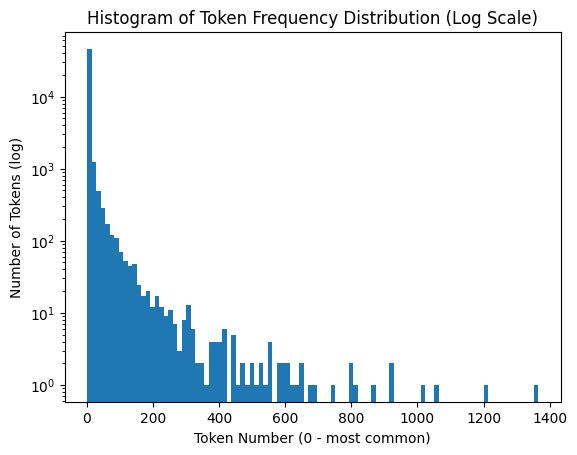


 The distribution shows a strong right skew. The top five most common words were 'new', 'date', 'get', 'please', and 'enron'. The distribution indicates that there are a few words that appear a lot, and there are a great many words that appear only a few times.

Q2 Training R^2: 0.7686
Q2 Test R^2: 0.6605

Top 10 Tokens By Absolute Coefficient:
background-image:    0.894673
localized            0.734777
transcript           0.704384
thermal              0.608732
rhythm               0.575916
aging                0.562800
cnet                 0.512514
xanaax               0.489885
april's              0.465511
premature            0.454109
dtype: float64

Top 5 Phishing-Associated Tokens:
localized     0.734777
transcript    0.704384
thermal       0.608732
rhythm        0.575916
aging         0.562800
dtype: float64

Top 5 Legitimate-Associated Tokens:
background-image:   -0.894673
cnet                -0.512514
april's             -0.465511
intervention        -0.432339
shopper        

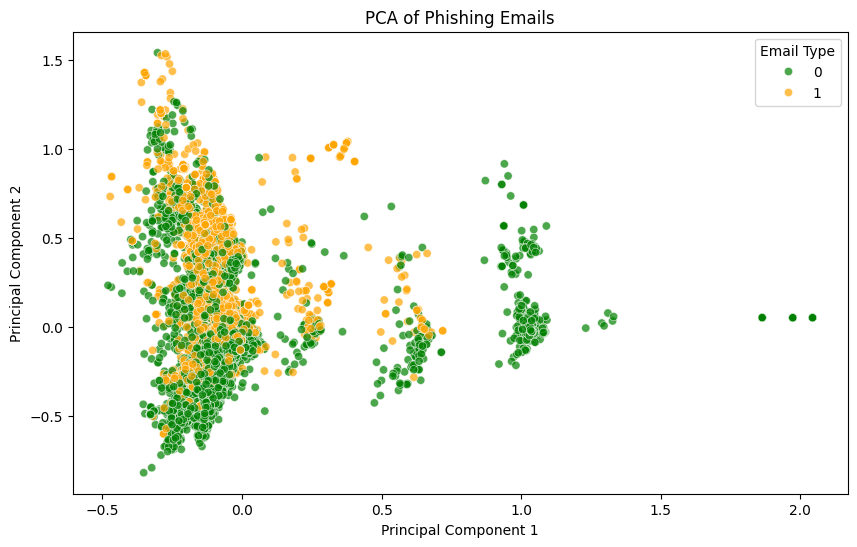


It appears that phishing and legitimate emails have a lot of overlap in what words they
use. However, there are some clusters free of phishing words (on the right of the graph 
past 1 on the x-axis), which appear to signal that it is a legitimate email.


Q4 Training R^2 (PCA 2610): 0.7680
Q4 Test R^2 (PCA 2610): 0.6603

We see with this data that using PCA only gave a very slightly lower R^2 scores despite
using less data, which makes sense because information was lost. However, it is still
pretty similar, so the PCA seems to have gotten a good overview of the data.


It appears that phishing and legitimate emails have a lot of overlap in what words they
use. However, there are some clusters free of phishing words (on the right of the graph 
past 1 on the x-axis), which appear to signal that it is a legitimate email.

AI Explanation: Using principal components for high-dimensional regression reduces 
multicollinearity among correlated words, mitigates overfitting by filtering out 
lo

In [23]:
# Your Phase 2 solution to the problem goes here.
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import seaborn as sns

# Q1
with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()
frequencies = [count for token, count in token_freq]

# Use log scale to adjust for strong right skew
plt.hist(frequencies, bins=100, log=True)
plt.title('Histogram of Token Frequency Distribution (Log Scale)')
plt.xlabel('Token Number (0 - most common)')
plt.ylabel('Number of Tokens (log)')
plt.show()

print("\n The distribution shows a strong right skew. The top five most common words were 'new', 'date', 'get', 'please', and 'enron'. The distribution indicates that there are a few words that appear a lot, and there are a great many words that appear only a few times.")

# Q2

df = pd.read_parquet('Phishing_clean.parquet')
X = df.drop(columns=["Email Type"])
y = df["Email Type"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=55, stratify=y
)

# Run regression of y on one-hot-encoded emails
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print(f"\nQ2 Training R^2: {lr_model.score(X_train, y_train):.4f}")
print(f"Q2 Test R^2: {lr_model.score(X_test, y_test):.4f}")

# What words have the largest coefficients in absolute value and most strongly influence predictions?
coefficients = pd.Series(lr_model.coef_, index=X.columns)
print("\nTop 10 Tokens By Absolute Coefficient:")
print(coefficients.abs().sort_values(ascending=False).head(10))
print("\nTop 5 Phishing-Associated Tokens:")
print(coefficients.sort_values(ascending=False).head(5))
print("\nTop 5 Legitimate-Associated Tokens:")
print(coefficients.sort_values(ascending=True).head(5))

# Q3

pca = PCA(n_components=2).fit(X)
X_pca = pca.transform(X)

# AI Suggestion
# pca_2 = PCA(n_components=2)
# pca_2.fit(X_train)
# X_pca_full = pca_2.transform(X)

print("Rows and score columns:", X_pca.shape)
print("Sklearn:", pca.explained_variance_ratio_)
print("Cumulative variance:", np.sum(pca.explained_variance_ratio_) )

# Scatterplot

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=y,
    palette= {0: 'green', 1: 'orange'},
    alpha=0.7
)

plt.title('PCA of Phishing Emails')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

print("""
It appears that phishing and legitimate emails have a lot of overlap in what words they
use. However, there are some clusters free of phishing words (on the right of the graph
past 1 on the x-axis), which appear to signal that it is a legitimate email.
""")

# Q4

pca_2610 = PCA(n_components=2610)
X_train_pca2610 = pca_2610.fit_transform(X_train)
X_test_pca2610 = pca_2610.transform(X_test)

# Linear Regression
pca_lr = LinearRegression()
pca_lr.fit(X_train_pca2610, y_train)

y_train_pred = model.predict(X_train_pca)
y_test_pred = model.predict(X_test_pca)

print(f"\nQ4 Training R^2 (PCA 2610): {pca_lr.score(X_train_pca2610, y_train):.4f}")
print(f"Q4 Test R^2 (PCA 2610): {pca_lr.score(X_test_pca2610, y_test):.4f}")

print("""
We see with this data that using PCA only gave a very slightly lower R^2 scores despite
using less data, which makes sense because information was lost. However, it is still
pretty similar, so the PCA seems to have gotten a good overview of the data.
""")

# Q5

print("""
It appears that phishing and legitimate emails have a lot of overlap in what words they
use. However, there are some clusters free of phishing words (on the right of the graph
past 1 on the x-axis), which appear to signal that it is a legitimate email.

AI Explanation: Using principal components for high-dimensional regression reduces
multicollinearity among correlated words, mitigates overfitting by filtering out
low-variance noise components, lowers computational overhead, and stabilizes model
coefficient estimation compared to utilizing thousands of raw, sparse one-hot features.
""")



### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

Looking over the AI suggestions, the main improvements to the code were for streamlining the code to include calculations in print statements, which was nice for reducing the amount of lines. It is also nice for checking your logic, granted it provides good reasoning. Most limitations from their suggestions stemmed from the AI possibly not being able to see the actual output of the original or its code, or not being given enough information or context. For instance, the AI said some things in the original would cause errors when they didn't on my end, so I left it as is. Thus, I think better prompting with more information, guidance, more specific questions, and follow-ups would improve the suggestions. Overall, making sure to always test and check the AI code to make sure the output aligns with your expectations, and knowing that how you prompt the AI is crucial to the quality of its outputs.